<a href="https://colab.research.google.com/github/ManasaRPatel/MachineLearning2_LAB/blob/main/xai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install shap -q

In [2]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Configure SHAP to output JavaScript visualizations in the notebook
shap.initjs()

In [3]:
# Load dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Calculate accuracy
accuracy = model.score(X_test, y_test)
print(f"Model Accuracy on Test Set: {accuracy:.4f}")

Model Accuracy on Test Set: 0.9649


In [4]:
# Initialize the Tree Explainer on our trained model
explainer = shap.TreeExplainer(model)

# Calculate SHAP values for the test set
shap_values = explainer(X_test)

--- Instance 1 (Index 0 in X_test) ---
True Label: benign
Predicted Label: benign (Probabilities: Malignant=0.03, Benign=0.97)


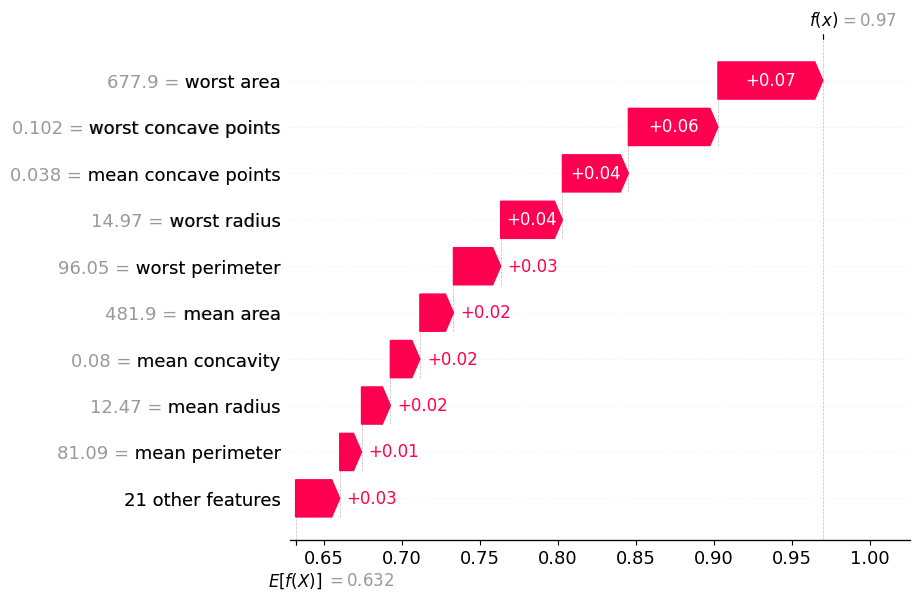

--- Instance 2 (Index 1 in X_test) ---
True Label: malignant
Predicted Label: malignant (Probabilities: Malignant=1.00, Benign=0.00)


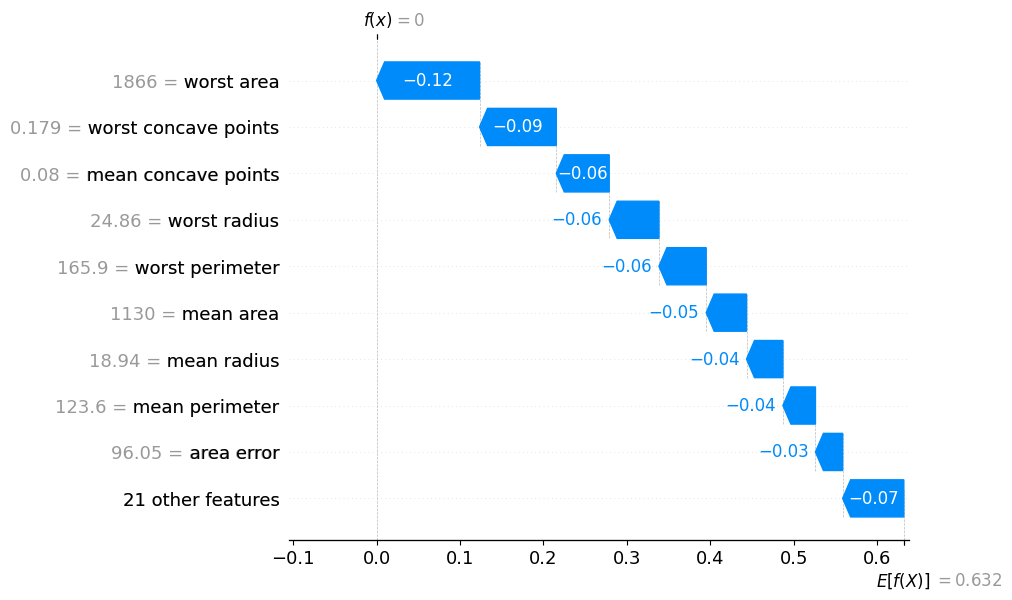

In [5]:
# Select 2 test instances
instance_1_idx = 0
instance_2_idx = 1

# True classes and predicted classes
pred_probs = model.predict_proba(X_test)

for i, idx in enumerate([instance_1_idx, instance_2_idx]):
    true_label = data.target_names[y_test[idx]]
    pred_label = data.target_names[model.predict(X_test.iloc[[idx]])[0]]
    prob = pred_probs[idx]

    print(f"--- Instance {i+1} (Index {idx} in X_test) ---")
    print(f"True Label: {true_label}")
    print(f"Predicted Label: {pred_label} (Probabilities: Malignant={prob[0]:.2f}, Benign={prob[1]:.2f})")

    # Plot local explanation for Benign class (class index 1)
    plt.figure()
    shap.plots.waterfall(shap_values[idx, :, 1], max_display=10)
    plt.show()